# CPU and GPU Monte Carlo on your laptop

Author: Fred J. Hickernell · MATH 565, Fall 2026

Companion to **Selected Topics: parallel computing**, adapted from the Fall 2025 GPU demo

Compare the same Monte Carlo calculation using NumPy CPU float64/float32, PyTorch CPU float32, and an available GPU in float32. Then evaluate many expectations together using bounded batches

**On M5:** select the course `qmcpy` kernel and Run All. The device summary should report **MPS — Apple GPU**. This notebook never changes system power settings or installs packages locally. If PyTorch is missing, the NumPy comparisons still run; install the optional dependency in the course environment with `python -m pip install torch`, restart the kernel, and rerun

The default workload is intended for a classroom demonstration. Adjust the parameter cell after the first run. GPU speedup depends on hardware, workload, precision, and overhead; it is not promised

Local execution is the intended M5 workflow. The conditional setup cell also supports the course's usual Colab environment, where an available CUDA GPU may be used

In [1]:
from pathlib import Path
import shutil
import subprocess
import sys
import time

NOTEBOOK_START_TIME = time.perf_counter()

colab = "google.colab" in sys.modules
if colab:
    print("Setting up this course's recorded classlib, QMCPy, and TeX; this may take several minutes …")
    course_checkout = Path("/content/MATH565Fall2026")
    if not course_checkout.exists():
        subprocess.run(
            [
                "git", "clone", "--quiet", "--depth", "1",
                "https://github.com/fjhickernell/MATH565Fall2026.git",
                str(course_checkout),
            ],
            check=True,
        )
    subprocess.run(
        [
            "git", "-C", str(course_checkout),
            "-c", "submodule.classlib.url=https://github.com/fjhickernell/HickernellAcademicLib.git",
            "-c", "submodule.qmcpy.url=https://github.com/QMCSoftware/qmcpy.git",
            "submodule", "update", "--init", "classlib", "qmcpy",
        ],
        check=True,
    )
    if shutil.which("latex") is None:
        subprocess.run(
            [
                "apt-get", "-qq", "install", "-y",
                "cm-super", "dvipng", "texlive-latex-extra",
                "texlive-latex-recommended",
            ],
            check=True,
        )
    subprocess.run(
        [
            sys.executable, "-m", "pip", "install", "-q",
            str(course_checkout / "classlib"),
            str(course_checkout / "qmcpy"),
        ],
        check=True,
    )
    print("Colab setup complete.")
    print("For faster repeated work, use the local `qmcpy` environment.")

In [2]:
import platform
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import classlib as cl
from IPython.display import display

cl.nbviz.init(use_tex=True)
colors = cl.nbviz.TOL_BRIGHT

try:
    import torch
except ImportError:
    torch = None

# Change parameters here, then Run All
SEED = 5652026
FORCE_CPU = False
D = 12
SAMPLE_SIZES = [2**12, 2**15, 2**18]
REPLICATIONS = 6
SAMPLE_BATCH = 2**12
MANY_N = 2**15
CENTER_COUNTS = [1, 8, 32, 128]
CENTER_BATCH = 32
MANY_REPLICATIONS = 3

assert D >= 1 and REPLICATIONS >= 2 and MANY_REPLICATIONS >= 2
assert SAMPLE_BATCH > 0 and CENTER_BATCH > 0 and MANY_N > 0
assert all(n > 0 for n in SAMPLE_SIZES + CENTER_COUNTS)

if torch is not None and not FORCE_CPU and torch.backends.mps.is_available():
    gpu_device = 'mps'
elif torch is not None and not FORCE_CPU and torch.cuda.is_available():
    gpu_device = 'cuda'
else:
    gpu_device = None

print(f'Python {platform.python_version()} | {platform.machine()} | {os.cpu_count()} logical CPU cores')
print(f'NumPy {np.__version__} | PyTorch {torch.__version__ if torch is not None else "not installed"}')
print('GPU backend:', {'mps': 'MPS — Apple GPU', 'cuda': 'CUDA — NVIDIA GPU'}.get(gpu_device, 'none — GPU rows are skipped'))
print(f'NumPy baseline: float64 and float32 | dimension {D} | {REPLICATIONS} replications')
print(f'Sample sizes: {SAMPLE_SIZES} | sample batch: {SAMPLE_BATCH}')
print('Saved timings describe the machine that executed the notebook; rerun on M5 for M5 results')

Python 3.13.13 | arm64 | 14 logical CPU cores
NumPy 2.4.6 | PyTorch 2.12.0
GPU backend: MPS — Apple GPU
NumPy baseline: float64 and float32 | dimension 12 | 6 replications
Sample sizes: [4096, 32768, 262144] | sample batch: 4096
Saved timings describe the machine that executed the notebook; rerun on M5 for M5 results


## Same expectation, different hardware

For $\boldsymbol X\sim\operatorname{Norm}(\boldsymbol0,I_d)$, estimate
\[
\mu=\mathbb E[f(\boldsymbol X)]=1,
\qquad f(\boldsymbol x)=2^{d/2}\exp(-\|\boldsymbol x\|^2/2)
\]
The normalization makes the exact answer one in every dimension. Also
\[
\operatorname{var}\{f(\boldsymbol X)\}=(2/\sqrt3)^d-1,
\qquad \operatorname{RMSE}(\widehat\mu_n)=\sqrt{\operatorname{var}\{f(\boldsymbol X)\}/n}
\]

This notebook deliberately uses **native NumPy/PyTorch random generators** to include generation in each backend's timing. It benchmarks hardware implementations rather than introducing another course sampling interface. NumPy and PyTorch seeds do not generate identical samples

CPU float32 versus CPU float64 explores precision and implementation cost. PyTorch CPU float32 versus PyTorch GPU float32 gives a closer comparison of hardware backends. Separate backend kernels and generators still differ

In [3]:
def synchronize(device):
    if torch is not None and device == 'mps':
        torch.mps.synchronize()
    elif torch is not None and device == 'cuda':
        torch.cuda.synchronize()


def seed_torch(seed):
    torch.manual_seed(seed)
    if gpu_device == 'mps':
        torch.mps.manual_seed(seed)
    elif gpu_device == 'cuda':
        torch.cuda.manual_seed_all(seed)


def numpy_mean(n, d, seed, dtype):
    rng = np.random.default_rng(seed)
    total = np.float64(0)
    for start in range(0, n, SAMPLE_BATCH):
        size = min(SAMPLE_BATCH, n-start)
        x = rng.standard_normal((size, d), dtype=dtype)
        squared_norm = np.sum(x*x, axis=1, dtype=dtype)
        values = np.exp(-dtype(0.5)*squared_norm) * dtype(2**(d/2))
        total += values.sum(dtype=dtype)
    return float(total/n)


def torch_mean(n, d, seed, device):
    seed_torch(seed)
    with torch.inference_mode():
        total = torch.zeros((), device=device, dtype=torch.float32)
        for start in range(0, n, SAMPLE_BATCH):
            size = min(SAMPLE_BATCH, n-start)
            x = torch.randn((size, d), device=device, dtype=torch.float32)
            values = torch.exp(-0.5*(x*x).sum(dim=1)) * (2**(d/2))
            total += values.sum()
        return float((total/n).item())


methods = [
    ('NumPy CPU64', 'cpu', lambda n, d, seed: numpy_mean(n, d, seed, np.float64)),
    ('NumPy CPU32', 'cpu', lambda n, d, seed: numpy_mean(n, d, seed, np.float32)),
]
if torch is not None:
    methods.append(('Torch CPU32', 'cpu', lambda n, d, seed: torch_mean(n, d, seed, 'cpu')))
if gpu_device is not None:
    methods.append((f'Torch {gpu_device.upper()}32', gpu_device,
                    lambda n, d, seed: torch_mean(n, d, seed, gpu_device)))


def timed_call(func, device, *args):
    synchronize(device)
    started = time.perf_counter()
    result = func(*args)
    synchronize(device)
    return result, time.perf_counter()-started


# Warm up kernels and device initialization outside measured replications
for _, device, func in methods:
    func(min(SAMPLE_BATCH, SAMPLE_SIZES[0]), D, SEED-1)
    synchronize(device)
print('Methods:', ', '.join(name for name, _, _ in methods))

Methods: NumPy CPU64, NumPy CPU32, Torch CPU32, Torch MPS32


## Timing independent complete runs

Each timed run includes sample generation, integrand evaluation, batch reductions, and return of the estimate to the CPU. GPU synchronization prevents asynchronous work from escaping the timer. Warmup, plotting, and notebook setup are excluded

All methods use the same batch limit. Seed assignment is explicit, with a separate seed for every method, sample size, and replication. Timings remain machine-specific and can change with background activity and power mode

In [4]:
records = []
for j, n in enumerate(SAMPLE_SIZES):
    for r in range(REPLICATIONS):
        # Rotate order to reduce systematic first/last-method timing effects
        order = list(range(len(methods)))
        order = order[r % len(order):] + order[:r % len(order)]
        for k in order:
            name, device, func = methods[k]
            seed = SEED + 100_000*k + 1000*j + r
            estimate, elapsed = timed_call(func, device, n, D, seed)
            records.append(dict(n=n, replication=r, method=name,
                                estimate=estimate, error=estimate-1, seconds=elapsed))
runs = pd.DataFrame(records)
assert np.isfinite(runs[['estimate', 'seconds']]).all().all()
assert (runs.seconds > 0).all()
summary = runs.groupby(['n', 'method'], sort=False).agg(
    mean_estimate=('estimate', 'mean'),
    empirical_RMSE=('error', lambda e: np.sqrt(np.mean(np.square(e)))),
    mean_seconds=('seconds', 'mean'),
).reset_index()
variance = (2/np.sqrt(3))**D - 1
summary['theoretical_RMSE'] = np.sqrt(variance/summary.n)
baseline = summary[summary.method == 'NumPy CPU64'].set_index('n').mean_seconds
summary['speedup_vs_NumPy64'] = summary.n.map(baseline)/summary.mean_seconds
display(summary.round(6))

,n,method,mean_estimate,empirical_RMSE,mean_seconds,theoretical_RMSE,speedup_vs_NumPy64
0,4096,NumPy CPU64,1.007425,0.044557,0.000353,0.033580,1.000000
1,4096,NumPy CPU32,1.003866,0.028524,0.000231,0.033580,1.526398
2,4096,Torch CPU32,0.985473,0.031931,0.001078,0.033580,0.327194
3,4096,Torch MPS32,1.018207,0.036566,0.001111,0.033580,0.317366
4,32768,NumPy CPU64,0.997856,0.012467,0.002015,0.011872,1.000000
5,32768,NumPy CPU32,1.003794,0.008655,0.001456,0.011872,1.383690
6,32768,Torch CPU32,0.994614,0.006959,0.004802,0.011872,0.419688
7,32768,Torch MPS32,1.007272,0.016506,0.002787,0.011872,0.723078
8,262144,NumPy CPU64,1.002348,0.003723,0.014874,0.004197,1.000000
9,262144,NumPy CPU32,0.999619,0.002914,0.010632,0.004197,1.399019


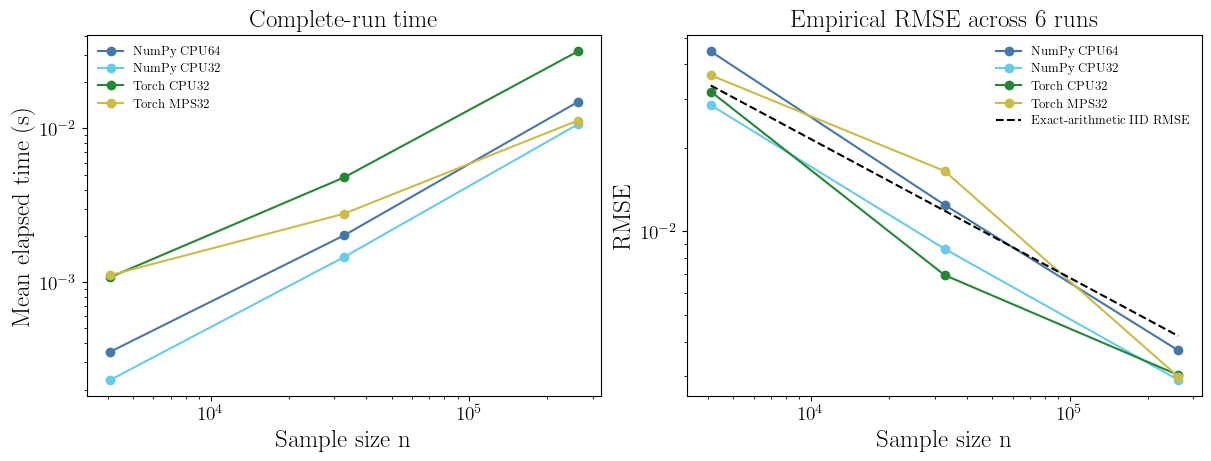

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for name, _, _ in methods:
    rows = summary[summary.method == name].sort_values('n')
    axes[0].loglog(rows.n, rows.mean_seconds, '-o', label=name)
    axes[1].loglog(rows.n, rows.empirical_RMSE, '-o', label=name)
axes[1].loglog(SAMPLE_SIZES, np.sqrt(variance/np.array(SAMPLE_SIZES)), '--',
               color='black', label='Exact-arithmetic IID RMSE')
axes[0].set(xlabel='Sample size n', ylabel='Mean elapsed time (s)', title='Complete-run time')
axes[1].set(xlabel='Sample size n', ylabel='RMSE', title=f'Empirical RMSE across {REPLICATIONS} runs')
for ax in axes:
    ax.legend(fontsize=9)
plt.show()

### Read the comparison

- Where does GPU throughput outweigh launch, batch, and synchronization overhead?
- Compare Torch CPU32 and GPU32 before attributing all NumPy64/GPU32 differences to hardware
- Empirical RMSE from six runs is noisy; a lucky small error is not evidence of higher arithmetic accuracy
- The theoretical RMSE concerns exact-arithmetic IID sampling. Floating-point error and implementation details can alter results
- Smaller batches reduce memory use but may reduce GPU throughput. Try changing `SAMPLE_BATCH` after the initial run

## Many expectations together

For centers $\boldsymbol a_j$, compute
\[
\mu(\boldsymbol a_j)=\mathbb E\left[
\frac{\exp(-\|\boldsymbol X-\boldsymbol a_j\|^2/2)}
{2^{-d/2}\exp(-\|\boldsymbol a_j\|^2/4)}\right]=1
\]
Reuse each sample batch for every center. Expectations within a run are **correlated** because they share samples; their across-center spread is not a standard error

We form squared distances by matrix multiplication and batch both samples and centers. No array of shape `(number of centers, total sample size, dimension)` is allocated. At the defaults, the largest distance block has at most `4096 × 32` entries

Centers are modest shifts along the first coordinate to avoid turning this hardware example into an extreme importance-weight experiment

In [6]:
centers = np.zeros((max(CENTER_COUNTS), D), dtype=np.float64)
centers[:, 0] = np.linspace(-1, 1, len(centers))


def numpy_many(n, centers, seed, dtype):
    a = np.asarray(centers, dtype=dtype)
    rng = np.random.default_rng(seed)
    norm = dtype(2**(-D/2)) * np.exp(-dtype(0.25)*np.sum(a*a, axis=1))
    totals = np.zeros(len(a), dtype=np.float64)
    for start in range(0, n, SAMPLE_BATCH):
        size = min(SAMPLE_BATCH, n-start)
        x = rng.standard_normal((size, D), dtype=dtype)
        x2 = np.sum(x*x, axis=1)[:, None]
        for j in range(0, len(a), CENTER_BATCH):
            aa = a[j:j+CENTER_BATCH]
            squared = x2 + np.sum(aa*aa, axis=1)[None, :] - dtype(2)*(x @ aa.T)
            np.maximum(squared, 0, out=squared)
            values = np.exp(-dtype(0.5)*squared)/norm[j:j+len(aa)]
            totals[j:j+len(aa)] += values.sum(axis=0, dtype=dtype)
    return totals/n


def torch_many(n, centers, seed, device):
    seed_torch(seed)
    with torch.inference_mode():
        a = torch.as_tensor(centers, dtype=torch.float32, device=device)
        norm = (2**(-D/2))*torch.exp(-0.25*(a*a).sum(dim=1))
        totals = torch.zeros(len(a), dtype=torch.float32, device=device)
        for start in range(0, n, SAMPLE_BATCH):
            size = min(SAMPLE_BATCH, n-start)
            x = torch.randn((size, D), dtype=torch.float32, device=device)
            x2 = (x*x).sum(dim=1)[:, None]
            for j in range(0, len(a), CENTER_BATCH):
                aa = a[j:j+CENTER_BATCH]
                squared = (x2 + (aa*aa).sum(dim=1)[None, :] - 2*(x @ aa.T)).clamp_min(0)
                values = torch.exp(-0.5*squared)/norm[j:j+len(aa)]
                totals[j:j+len(aa)] += values.sum(dim=0)
        return (totals/n).cpu().numpy()


many_methods = [
    ('NumPy CPU64', 'cpu', lambda n, a, seed: numpy_many(n, a, seed, np.float64)),
    ('NumPy CPU32', 'cpu', lambda n, a, seed: numpy_many(n, a, seed, np.float32)),
]
if torch is not None:
    many_methods.append(('Torch CPU32', 'cpu', lambda n, a, seed: torch_many(n, a, seed, 'cpu')))
if gpu_device is not None:
    many_methods.append((f'Torch {gpu_device.upper()}32', gpu_device,
                         lambda n, a, seed: torch_many(n, a, seed, gpu_device)))
for _, device, func in many_methods:
    func(min(MANY_N, SAMPLE_BATCH), centers[:min(CENTER_BATCH, len(centers))], SEED-2)
    synchronize(device)

In [7]:
many_records = []
for j, count in enumerate(CENTER_COUNTS):
    for r in range(MANY_REPLICATIONS):
        order = list(range(len(many_methods)))
        order = order[r % len(order):] + order[:r % len(order)]
        for k in order:
            name, device, func = many_methods[k]
            estimates, elapsed = timed_call(func, device, MANY_N, centers[:count],
                                            SEED + 1_000_000 + 100_000*k + 1000*j + r)
            assert estimates.shape == (count,) and np.isfinite(estimates).all()
            many_records.append(dict(centers=count, method=name, seconds=elapsed,
                                     mean_absolute_error=np.mean(np.abs(estimates-1))))
many_runs = pd.DataFrame(many_records)
many_summary = many_runs.groupby(['centers', 'method'], sort=False).agg(
    mean_seconds=('seconds', 'mean'),
    mean_absolute_error=('mean_absolute_error', 'mean'),
).reset_index()
display(many_summary.round(6))

,centers,method,mean_seconds,mean_absolute_error
0,1,NumPy CPU64,0.002256,0.006386
1,1,NumPy CPU32,0.001491,0.011404
2,1,Torch CPU32,0.004880,0.010576
3,1,Torch MPS32,0.006740,0.003447
4,8,NumPy CPU64,0.003249,0.006509
5,8,NumPy CPU32,0.002526,0.012433
6,8,Torch CPU32,0.005538,0.006250
7,8,Torch MPS32,0.007252,0.012853
8,32,NumPy CPU64,0.007960,0.010952
9,32,NumPy CPU32,0.004525,0.018856


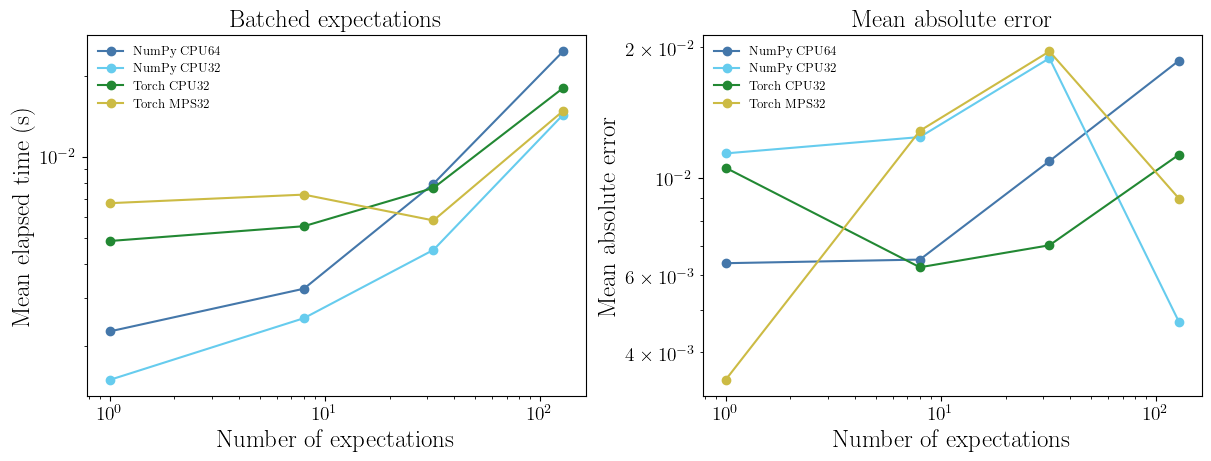

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for name, _, _ in many_methods:
    rows = many_summary[many_summary.method == name].sort_values('centers')
    axes[0].loglog(rows.centers, rows.mean_seconds, '-o', label=name)
    axes[1].loglog(rows.centers, rows.mean_absolute_error, '-o', label=name)
axes[0].set(xlabel='Number of expectations', ylabel='Mean elapsed time (s)', title='Batched expectations')
axes[1].set(xlabel='Number of expectations', ylabel='Mean absolute error', title='Mean absolute error')
for ax in axes:
    ax.legend(fontsize=9)
plt.show()

## Discussion and M5 check

- Confirm that the summary says **MPS — Apple GPU** before interpreting a row as GPU timing
- Find the workloads where GPU32 beats Torch CPU32 and NumPy CPU64. A CPU win at small sizes is useful evidence about overhead
- Try `SAMPLE_BATCH = 2**14` or larger sample sizes, changing one setting at a time. Batches bound temporary arrays, although larger user-selected parameters still require more work and memory
- More expectations need not improve statistical accuracy. They supply more work that can be evaluated concurrently
- Float32 changes arithmetic precision; parallelism changes cost. Neither replaces a valid sampling design or error assessment

Please compare the M5 results with these saved Mini results. No M5 validation is claimed until you run the notebook there

In [9]:
notebook_elapsed = time.perf_counter() - NOTEBOOK_START_TIME
notebook_minutes, notebook_seconds = divmod(notebook_elapsed, 60)
print(
    "Total execution time for this notebook is "
    f"{int(notebook_minutes)} min {notebook_seconds:.1f} sec."
)

Total execution time for this notebook is 0 min 3.3 sec.
